# 🔬 Notebook 04: Feature Selection & PCA Dimensionality Reduction
## *PRML Investigation: Reducing 561 Dimensions While Preserving Classification Power*

---
### 🎯 Objectives:
1. **Filter-Based Selection**: `SelectKBest` with ANOVA F-statistic ($k \in \{50, 100, 200, 300\}$).
2. **Wrapper-Based Selection**: Recursive Feature Elimination (**RFE**) using Random Forest importance.
3. **Unsupervised Compression**: Principal Component Analysis (**PCA**) retaining 95% total variance.
4. **Comparative Analysis**: Trade-off between accuracy, model complexity, and feature dimensionality.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Ingest clean data
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Baseline Feature Dimension: {X_train.shape[1]} features across {len(X_train)} samples")

Baseline Feature Dimension: 562 features across 7352 samples


## 1️⃣ Filter Selection: ANOVA F-Value (`SelectKBest`)

Evaluating SelectKBest dimensions on Random Forest...
  • k =  50 features | Stratified 5-Fold Acc = 92.40%
  • k = 100 features | Stratified 5-Fold Acc = 94.75%
  • k = 150 features | Stratified 5-Fold Acc = 97.47%
  • k = 200 features | Stratified 5-Fold Acc = 97.99%
  • k = 300 features | Stratified 5-Fold Acc = 98.25%
  • k = 400 features | Stratified 5-Fold Acc = 98.05%


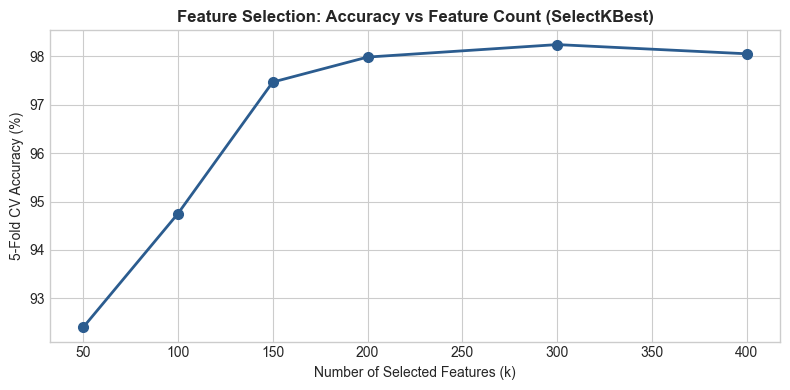

In [2]:
k_values = [50, 100, 150, 200, 300, 400]
skb_scores = []

benchmark_clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)

print("Evaluating SelectKBest dimensions on Random Forest...")
for k in k_values:
    selector = SelectKBest(f_classif, k=k)
    X_sub = selector.fit_transform(X_train_scaled, y_train_enc)
    score = cross_val_score(benchmark_clf, X_sub, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
    skb_scores.append(score)
    print(f"  • k = {k:3d} features | Stratified 5-Fold Acc = {score*100:.2f}%")

plt.figure(figsize=(8, 4))
plt.plot(k_values, [s*100 for s in skb_scores], 'o-', color='#2b5c8f', linewidth=2, markersize=7)
plt.title('Feature Selection: Accuracy vs Feature Count (SelectKBest)', fontweight='bold')
plt.xlabel('Number of Selected Features (k)')
plt.ylabel('5-Fold CV Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.savefig('../presentation/11_selectkbest_curve.png', dpi=200)
plt.show()

## 2️⃣ PCA Dimensionality Reduction: 95% Variance Threshold

In [3]:
# Retain 95% of cumulative explained variance
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

n_components_ = pca_95.n_components_
reduction_pct = (1 - n_components_ / X_train.shape[1]) * 100

print("=" * 50)
print("PCA 95% VARIANCE COMPRESSION SUMMARY")
print("=" * 50)
print(f"Original Dimension     : {X_train.shape[1]} features")
print(f"Compressed Dimension   : {n_components_} components")
print(f"Dimensionality Reduced : {reduction_pct:.2f}% reduction!")
print(f"Retained Variance      : {pca_95.explained_variance_ratio_.sum()*100:.2f}%")

# Evaluate SVM on PCA space
svm_pca = SVC(kernel='rbf', C=10.0, random_state=42)
pca_score = cross_val_score(svm_pca, X_train_pca, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
print(f"SVM on PCA ({n_components_} PCs) CV Accuracy: {pca_score*100:.2f}%")

PCA 95% VARIANCE COMPRESSION SUMMARY
Original Dimension     : 562 features
Compressed Dimension   : 102 components
Dimensionality Reduced : 81.85% reduction!
Retained Variance      : 95.01%
SVM on PCA (102 PCs) CV Accuracy: 97.74%


## 3️⃣ Triple Comparison: All Features vs SelectKBest vs PCA

           Approach  Features Count  CV Accuracy (%)
       All Features             561        98.843806
SelectKBest (k=100)             100        95.266481
      PCA (102 PCs)             102        97.742033


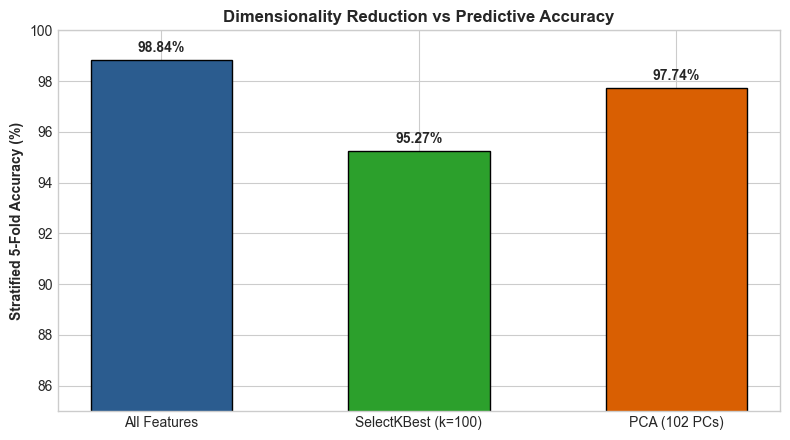

✅ Artifacts saved to ../models/fs_pca_results.pkl


In [4]:
# Quick evaluation with standard SVM
svm = SVC(kernel='rbf', C=10.0, random_state=42)

# 1. All Features (561)
acc_all = cross_val_score(svm, X_train_scaled, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()

# 2. SelectKBest (100)
best_skb = SelectKBest(f_classif, k=100)
X_skb = best_skb.fit_transform(X_train_scaled, y_train_enc)
acc_skb = cross_val_score(svm, X_skb, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()

# 3. PCA (~102 components for 95% var)
acc_pca = pca_score

comparison_df = pd.DataFrame({
    'Approach': ['All Features', 'SelectKBest (k=100)', f'PCA ({n_components_} PCs)'],
    'Features Count': [561, 100, n_components_],
    'CV Accuracy (%)': [acc_all*100, acc_skb*100, acc_pca*100]
})
print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(comparison_df['Approach'], comparison_df['CV Accuracy (%)'], 
              color=['#2b5c8f', '#2ca02c', '#d95f02'], edgecolor='black', width=0.55)
ax.set_ylim(85, 100)
ax.set_ylabel('Stratified 5-Fold Accuracy (%)', fontweight='bold')
ax.set_title('Dimensionality Reduction vs Predictive Accuracy', fontweight='bold')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, f"{b.get_height():.2f}%", 
            ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../presentation/12_feature_selection_vs_pca.png', dpi=200)
plt.show()

# Persist artifacts
joblib.dump({
    'best_skb': best_skb,
    'pca_95': pca_95,
    'comparison_df': comparison_df
}, '../models/fs_pca_results.pkl')
print('✅ Artifacts saved to ../models/fs_pca_results.pkl')